# Feature Engineering orientado a negocio

## Proyecto: SaaS Customer Churn Intelligence

En esta fase transformaremos el dataset limpio obtenido en el EDA en un dataset preparado para las siguientes fases.

El objetivo **no es crear muchas variables**, sino construir variables sencillas, explicables y relacionadas con el problema de negocio.

### Objetivos
- Crear variables derivadas a partir de las variables existentes.
- Incorporar información de antigüedad, facturación, contrato y servicios.
- Evitar variables que utilicen directamente el target `Churn`.
- Guardar el resultado en `data/processed/features.parquet`.

> Esta fase no pretende demostrar todavía qué variables son las más importantes. Eso se analizará durante el modelado.

## 1. Contexto de negocio

El proyecto busca ayudar a una empresa SaaS B2B a identificar clientes con mayor riesgo de abandono y entender qué características están asociadas al churn.

El EDA mostró patrones relacionados con:
- la antigüedad (`tenure`)
- el importe mensual (`MonthlyCharges`)
- el tipo de contrato (`Contract`)
- determinados servicios
- el método de pago

El objetivo ahora es crear algunas variables derivadas que sean más fáciles de interpretar desde negocio.

## 2. Carga del dataset limpio

Partimos del dataset generado al finalizar el EDA:

`data/processed/cleaned.parquet`

El dataset original de `data/raw/` no se modifica.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

DATA_PATH = Path("../data/processed/cleaned.parquet")

df = pd.read_parquet(DATA_PATH)

print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

df.head()

Filas: 7,043
Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Validación inicial de granularidad
initial_rows = len(df)

if not df["customerID"].is_unique:
    raise ValueError("customerID contiene duplicados. Cada fila debe representar un único cliente.")

if df["customerID"].isna().any():
    raise ValueError("Hay customerID nulos.")

print(f"Filas iniciales: {initial_rows:,}")
print(f"Clientes únicos: {df['customerID'].nunique():,}")


Filas iniciales: 7,043
Clientes únicos: 7,043


## 3. Comprobaciones iniciales

Antes de crear variables nuevas comprobamos que las columnas necesarias existen y que las variables numéricas tienen el tipo correcto.

In [3]:
required_columns = [
    "tenure", "MonthlyCharges", "TotalCharges",
    "Contract", "OnlineSecurity", "TechSupport",
    "OnlineBackup", "DeviceProtection",
    "StreamingTV", "StreamingMovies",
    "PhoneService", "MultipleLines",
    "InternetService", "PaymentMethod", "Churn"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Faltan columnas necesarias: {missing_columns}")

display(df[["tenure", "MonthlyCharges", "TotalCharges"]].dtypes)

tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object

## 4. Variable de antigüedad: `tenure_group`

El EDA mostró una diferencia entre clientes con poca y mucha antigüedad.

Para negocio puede ser más fácil trabajar con grupos:
- `0-12 months`
- `13-24 months`
- `25-48 months`
- `49+ months`

Conservamos también `tenure`, porque los meses exactos siguen siendo útiles para el modelado.

In [4]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, np.inf],
    labels=["0-12 months", "13-24 months", "25-48 months", "49+ months"]
)

df["tenure_group"].value_counts(sort=False)

tenure_group
0-12 months     2186
13-24 months    1024
25-48 months    1594
49+ months      2239
Name: count, dtype: int64

## 5. Variable de facturación: `monthly_charge_group`

`MonthlyCharges` es útil como variable numérica, pero para negocio también puede ser interesante agrupar clientes por nivel de facturación.

Utilizamos tres grupos basados en terciles:
- `Low`
- `Medium`
- `High`

Los límites se calculan sin utilizar `Churn`.

> **Nota sobre train/test:** los puntos de corte (`q1` y `q2`) se calculan sobre el dataset completo en esta fase porque esta transformación se utiliza como agrupación descriptiva del análisis. Si esta variable se utiliza directamente en un modelo, los puntos de corte deberán calcularse únicamente con el conjunto de entrenamiento y aplicarse después al test.


In [5]:
charge_q1 = df["MonthlyCharges"].quantile(1/3)
charge_q2 = df["MonthlyCharges"].quantile(2/3)

df["monthly_charge_group"] = pd.cut(
    df["MonthlyCharges"],
    bins=[-np.inf, charge_q1, charge_q2, np.inf],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print(f"Límite Low/Medium: {charge_q1:.2f}")
print(f"Límite Medium/High: {charge_q2:.2f}")
df["monthly_charge_group"].value_counts(sort=False)

Límite Low/Medium: 50.40
Límite Medium/High: 83.90


monthly_charge_group
Low       2351
Medium    2345
High      2347
Name: count, dtype: int64

## 6. Indicador de contrato mensual: `is_monthly_contract`

El EDA mostró una asociación importante entre tipo de contrato y churn.

Creamos:
- `1` → contrato mensual
- `0` → contrato de uno o dos años

Esto facilita análisis posteriores y el modelado.

> Es una asociación observada, no una afirmación de causalidad.

In [6]:
df["is_monthly_contract"] = (
    df["Contract"] == "Month-to-month"
).astype(int)

df["is_monthly_contract"].value_counts()

is_monthly_contract
1    3875
0    3168
Name: count, dtype: int64

## 7. Número de servicios adicionales: `num_services_contracted`

Creamos un contador de servicios adicionales contratados:

- OnlineSecurity
- OnlineBackup
- DeviceProtection
- TechSupport
- StreamingTV
- StreamingMovies

Solo el valor `Yes` suma un servicio. `PhoneService` y `MultipleLines` no se incluyen porque describen el servicio telefónico y no queremos contarlos como servicios adicionales independientes.

In [7]:
# Contamos únicamente servicios adicionales.
# MultipleLines no se incluye porque es una característica del servicio telefónico
# y no queremos contarla como un servicio independiente.
additional_service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["num_services_contracted"] = (
    df[additional_service_columns]
    .eq("Yes")
    .sum(axis=1)
)

df["num_services_contracted"].value_counts().sort_index()

num_services_contracted
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: count, dtype: int64

## 8. Indicadores de servicios

Creamos dos indicadores sencillos:
- `has_tech_support`
- `has_online_security`

`1` significa que el cliente tiene contratado el servicio y `0` que no lo tiene.

Estas variables simplifican el uso de las categorías originales en el modelado posterior.

In [8]:
df["has_tech_support"] = (
    df["TechSupport"] == "Yes"
).astype(int)

df["has_online_security"] = (
    df["OnlineSecurity"] == "Yes"
).astype(int)

display(df[[
    "TechSupport", "has_tech_support",
    "OnlineSecurity", "has_online_security"
]].head())

,TechSupport,has_tech_support,OnlineSecurity,has_online_security
0,No,0,No,0
1,No,0,Yes,1
2,No,0,Yes,1
3,Yes,1,Yes,1
4,No,0,No,0


## 9. Indicador de método de pago electrónico

El EDA mostró una asociación entre `Electronic check` y una mayor proporción de churn.

Creamos:
- `1` → Electronic check
- `0` → resto

Es una transformación sencilla de una categoría concreta que puede resultar útil para análisis y modelado.

In [9]:
df["uses_electronic_check"] = (
    df["PaymentMethod"] == "Electronic check"
).astype(int)

df["uses_electronic_check"].value_counts()

uses_electronic_check
0    4678
1    2365
Name: count, dtype: int64

## 10. Revisión de las nuevas variables

In [10]:
new_features = [
    "tenure_group",
    "monthly_charge_group",
    "is_monthly_contract",
    "num_services_contracted",
    "has_tech_support",
    "has_online_security",
    "uses_electronic_check"
]

display(df[new_features].head())

,tenure_group,monthly_charge_group,is_monthly_contract,num_services_contracted,has_tech_support,has_online_security,uses_electronic_check
0,0-12 months,Low,1,1,0,0,1
1,25-48 months,Medium,0,2,0,1,0
2,0-12 months,Medium,1,2,0,1,0
3,25-48 months,Low,0,3,1,1,0
4,0-12 months,Medium,1,0,0,0,1


## 11. Comprobación rápida frente al churn

Esta sección **no sustituye al modelado**.

Solo comprobamos que las nuevas variables mantienen patrones coherentes con el EDA.

No utilizamos estos resultados para afirmar causalidad ni para seleccionar todavía las mejores variables.

In [11]:
def churn_rate_by(column):
    return (
        df.groupby(column, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
        .round(2)
    )

for feature in [
    "tenure_group",
    "monthly_charge_group",
    "is_monthly_contract",
    "has_tech_support",
    "has_online_security",
    "uses_electronic_check"
]:
    print(f"\nChurn por {feature}:")
    display(churn_rate_by(feature))


Churn por tenure_group:


tenure_group
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49+ months       9.51
Name: Churn, dtype: float64


Churn por monthly_charge_group:


monthly_charge_group
High      34.09
Medium    29.68
Low       15.87
Name: Churn, dtype: float64


Churn por is_monthly_contract:


...

has_tech_support
0    31.19
1    15.17
Name: Churn, dtype: float64


Churn por has_online_security:


has_online_security
0    31.33
1    14.61
Name: Churn, dtype: float64


Churn por uses_electronic_check:


uses_electronic_check
1    45.29
0    17.06
Name: Churn, dtype: float64

## 12. Visualización sencilla

Comprobamos visualmente la distribución de dos de las nuevas variables.

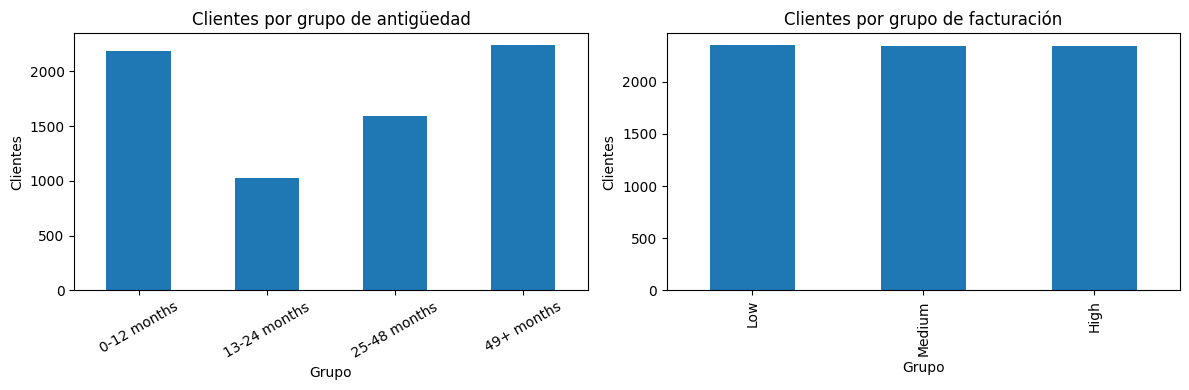

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["tenure_group"].value_counts(sort=False).plot(kind="bar", ax=axes[0])
axes[0].set_title("Clientes por grupo de antigüedad")
axes[0].set_xlabel("Grupo")
axes[0].set_ylabel("Clientes")
axes[0].tick_params(axis="x", rotation=30)

df["monthly_charge_group"].value_counts(sort=False).plot(kind="bar", ax=axes[1])
axes[1].set_title("Clientes por grupo de facturación")
axes[1].set_xlabel("Grupo")
axes[1].set_ylabel("Clientes")

plt.tight_layout()
plt.show()

## 13. Variables creadas

| Variable | Tipo | Objetivo |
|---|---|---|
| `tenure_group` | Categórica | Agrupar antigüedad |
| `monthly_charge_group` | Categórica | Agrupar facturación |
| `is_monthly_contract` | Binaria | Identificar contrato mensual |
| `num_services_contracted` | Numérica | Medir número de servicios |
| `has_tech_support` | Binaria | Indicador de soporte |
| `has_online_security` | Binaria | Indicador de seguridad |
| `uses_electronic_check` | Binaria | Identificar método de pago |

La selección es deliberadamente pequeña. Más variables no implica automáticamente un mejor análisis.

> **Nota sobre train/test:** los puntos de corte (`q1` y `q2`) se calculan sobre el dataset completo en esta fase porque esta transformación se utiliza como agrupación descriptiva del análisis. Si esta variable se utiliza directamente en un modelo, los puntos de corte deberán calcularse únicamente con el conjunto de entrenamiento y aplicarse después al test.


## 14. Preparación básica del target

Para la siguiente fase necesitaremos una variable binaria:
- `Yes` → `1`
- `No` → `0`

La versión original `Churn` se conserva.

In [13]:
df["churn_target"] = (
    df["Churn"] == "Yes"
).astype(int)

display(df[["Churn", "churn_target"]].head())

,Churn,churn_target
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


## 16. Revisión final

No eliminamos automáticamente los 11 valores vacíos de `TotalCharges` detectados en el EDA. Se mantienen como `NaN` para definir explícitamente el tratamiento de missing values durante la preparación del modelo.

In [14]:
print(f"Shape final: {df.shape}")

print("\nNuevas variables:")
print(new_features + ["churn_target"])

print("\nValores nulos:")
display(df.isna().sum().sort_values(ascending=False).head(10))

print("\nTipos de las nuevas variables:")
display(df[new_features + ["churn_target"]].dtypes)

Shape final: (7043, 29)

Nuevas variables:
['tenure_group', 'monthly_charge_group', 'is_monthly_contract', 'num_services_contracted', 'has_tech_support', 'has_online_security', 'uses_electronic_check', 'churn_target']

Valores nulos:


TotalCharges       11
gender              0
SeniorCitizen       0
Partner             0
customerID          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
dtype: int64


Tipos de las nuevas variables:


tenure_group               category
monthly_charge_group       category
is_monthly_contract           int64
num_services_contracted       int64
has_tech_support              int64
has_online_security           int64
uses_electronic_check         int64
churn_target                  int64
dtype: object

## 17. Validaciones finales

Antes de guardar el resultado, comprobamos que se mantiene la granularidad del dataset, que el target no se ha modificado y que las variables derivadas tienen rangos razonables.

In [15]:
# La granularidad debe mantenerse: una fila = un cliente
assert len(df) == initial_rows, "El número de filas ha cambiado durante el feature engineering."
assert df["customerID"].is_unique, "customerID contiene duplicados después del feature engineering."
assert df["customerID"].notna().all(), "Hay customerID nulos después del feature engineering."

# El target no debe haberse modificado
assert df["Churn"].notna().all(), "Hay valores nulos en Churn."

# Comprobamos que las nuevas variables tienen rangos razonables
assert df["num_services_contracted"].between(0, len(additional_service_columns)).all()
assert df["is_monthly_contract"].isin([0, 1]).all()
assert df["has_tech_support"].isin([0, 1]).all()
assert df["has_online_security"].isin([0, 1]).all()
assert df["uses_electronic_check"].isin([0, 1]).all()

print("Validaciones finales completadas correctamente.")
print(f"Filas: {len(df):,}")
print(f"Clientes únicos: {df['customerID'].nunique():,}")

Validaciones finales completadas correctamente.
Filas: 7,043
Clientes únicos: 7,043


## 18. Guardar dataset con features

El resultado se guarda en:

`data/processed/features.parquet`

El dataset original y `cleaned.parquet` no se modifican.

In [16]:
OUTPUT_PATH = Path("../data/processed/features.parquet")

df.to_parquet(OUTPUT_PATH, index=False)

print(f"Dataset guardado en: {OUTPUT_PATH}")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

Dataset guardado en: ..\data\processed\features.parquet
Filas: 7,043
Columnas: 29


# Resumen del feature engineering

## 1. Objetivo alcanzado

Se ha transformado el dataset limpio en un conjunto de datos preparado para la siguiente fase del proyecto. Las variables originales se han conservado y se han añadido únicamente transformaciones sencillas, interpretables y relacionadas con el comportamiento del cliente.

## 2. Variables creadas

Las nuevas variables resumen aspectos relevantes para el negocio:

- `tenure_group`: agrupa la antigüedad del cliente en cuatro etapas.
- `monthly_charge_group`: agrupa el cargo mensual en tres niveles.
- `is_monthly_contract`: identifica si el cliente tiene un contrato mensual.
- `num_services_contracted`: cuenta los servicios adicionales contratados.
- `has_tech_support` y `has_online_security`: indican la contratación de servicios concretos.
- `uses_electronic_check`: identifica el uso de este método de pago.
- `churn_target`: convierte `Churn` en una variable binaria para el modelado, conservando también la columna original.

Estas variables no demuestran por sí mismas que exista una relación causal con el churn. Su función es facilitar la interpretación y preparar la información para comprobar posteriormente su utilidad en un modelo.

## 3. Decisiones metodológicas

- `customerID` se mantiene como identificador, pero no se utilizará como predictor.
- `Churn` no se ha utilizado para crear variables predictoras.
- Se han mantenido las variables originales para no perder detalle.
- No se han creado interacciones complejas ni un CLV artificial.
- Las variables derivadas que resumen información original deberán compararse durante el modelado para evitar redundancias innecesarias.

## 4. Limitaciones y aspectos pendientes

`TotalCharges` conserva 11 valores faltantes detectados durante la limpieza. Su tratamiento se decidirá en la preparación del modelo. Además, los grupos de `MonthlyCharges` se han calculado sobre este dataset como transformación descriptiva; si se utilizan directamente en un modelo, sus puntos de corte deberán calcularse con el conjunto de entrenamiento.

## 5. Resultado y siguiente paso

El dataset con las variables creadas se ha guardado en `data/processed/features.parquet`. Todavía no se ha realizado el encoding de variables categóricas, división train/test ni entrenamiento.

El siguiente paso será separar las variables predictoras del target, preparar las variables categóricas y construir un modelo baseline que permita evaluar si las señales observadas ayudan a identificar clientes en riesgo.